# FE 5108 — Stage 2: the CAPM and the empirical SML

This notebook runs the security characteristic regression and the empirical
security market line for **both** the US and Singapore universes. All of the
logic lives in `goldman.analysis.capm`; the notebook is a thin driver, so
swapping the universe name or the market proxy is a one-line change.

- **(2a)** per-asset $\hat\beta_i$, $\hat\alpha_i$, $t(\hat\alpha_i)$, $R^2$
- **(2b)** the empirical SML with fitted and theoretical lines
- **(2c)** joint test that all alphas are zero (GRS) and the chance count
- **(2d)** fitted slope/intercept against the theory

Setup: `uv sync --extra notebook`, then *Kernel ▸ Restart & Run All*.

## Setup
Pick the universes; each is loaded and run with its own risk-free rate,
value weights and market proxy from the registry in `goldman.config`.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from goldman.analysis import run_capm_analysis
from goldman.config import get_universe
from goldman.data import load_ff3, load_returns

UNIVERSES = ["us", "sg"]
RESULTS = {}

for universe in UNIVERSES:
    returns = load_returns(universe=universe)
    with warnings.catch_warnings():
        # SG has no committed MAS/SORA series yet; the loader warns once.
        warnings.simplefilter("ignore")
        RESULTS[universe] = run_capm_analysis(returns, universe=universe)
    spec = get_universe(universe)
    print(
        f"{universe}: {returns.shape[1]} assets x {returns.shape[0]} months "
        f"({spec.currency}, market proxy = {RESULTS[universe].method})"
    )

us: 30 assets x 119 months (USD, market proxy = value_weighted)


sg: 29 assets x 119 months (SGD, market proxy = value_weighted)


## (2a) Security characteristic lines
The first few rows of each universe's $\hat\alpha$, $\hat\beta$,
$t(\hat\alpha)$ and $R^2$ table; the full tables are written to `outputs/`.

In [2]:
COLS = ["alpha", "beta", "t_alpha", "p_alpha", "r_squared", "n"]
for universe, result in RESULTS.items():
    print(f"--- {universe} ({result.output_paths['scl'].name}) ---")
    display(result.table[COLS].head(8).round(3))

--- us (capm_us_value_weighted_scl.csv) ---


,alpha,beta,t_alpha,p_alpha,r_squared,n
asset,,,,,,
AAPL,0.001,1.141,0.112,0.911,0.535,119
AMZN,-0.010,1.417,-1.777,0.078,0.631,119
BAC,-0.003,0.953,-0.491,0.624,0.339,119
CSCO,-0.001,0.773,-0.191,0.849,0.295,119
CVX,-0.000,0.575,-0.025,0.980,0.124,119
DIS,-0.016,1.035,-2.288,0.024,0.351,119
GOOGL,-0.002,1.119,-0.416,0.678,0.527,119
HD,-0.003,0.693,-0.560,0.577,0.279,119


--- sg (capm_sg_value_weighted_scl.csv) ---


,alpha,beta,t_alpha,p_alpha,r_squared,n
asset,,,,,,
A17U.SI,-0.004,0.483,-1.043,0.299,0.212,119
AJBU.SI,0.005,0.235,0.914,0.362,0.029,119
BN4.SI,-0.001,1.227,-0.196,0.845,0.463,119
BS6.SI,0.017,0.911,1.791,0.076,0.103,119
BUOU.SI,-0.006,0.768,-1.058,0.292,0.213,119
C07.SI,-0.013,0.908,-2.221,0.028,0.251,119
C09.SI,-0.015,1.359,-3.013,0.003,0.486,119
C38U.SI,-0.006,0.739,-1.468,0.145,0.323,119


## (2b) Empirical SML
Average excess return against estimated beta, with the fitted cross-sectional
line and the CAPM's theoretical line through the origin.

--- us ---


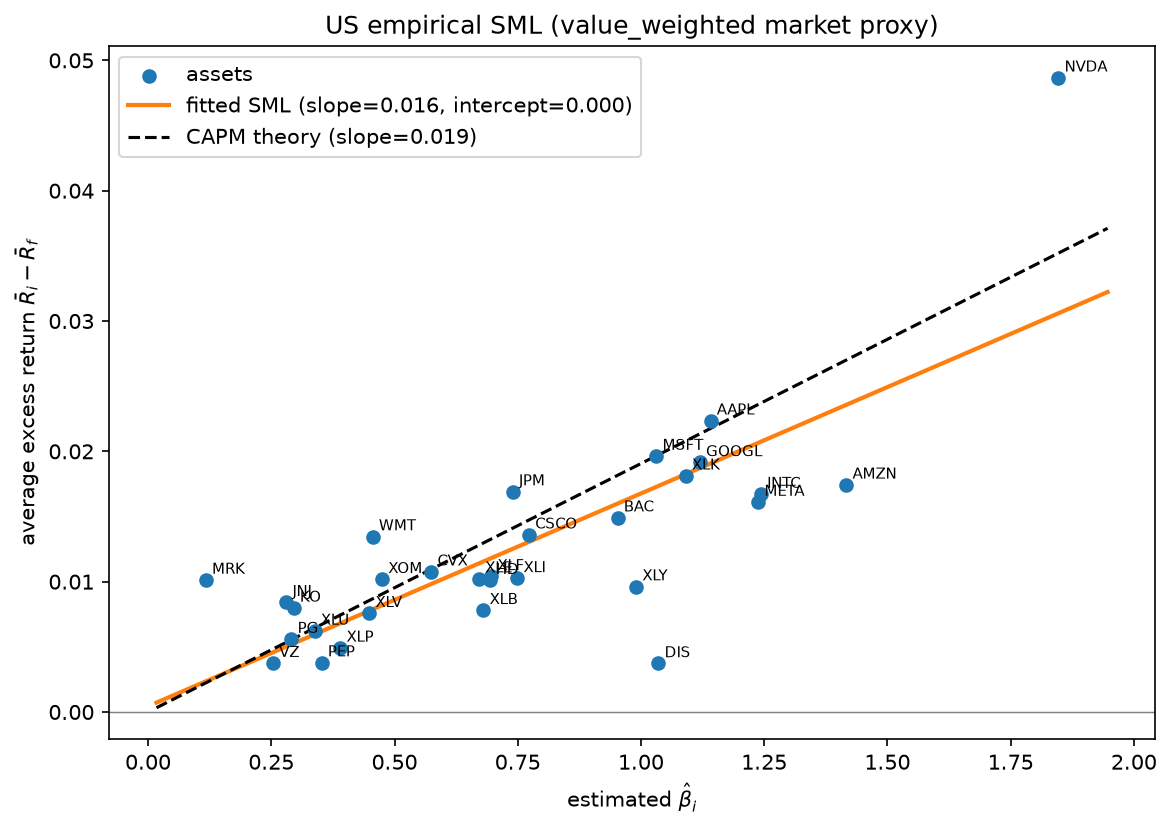

--- sg ---


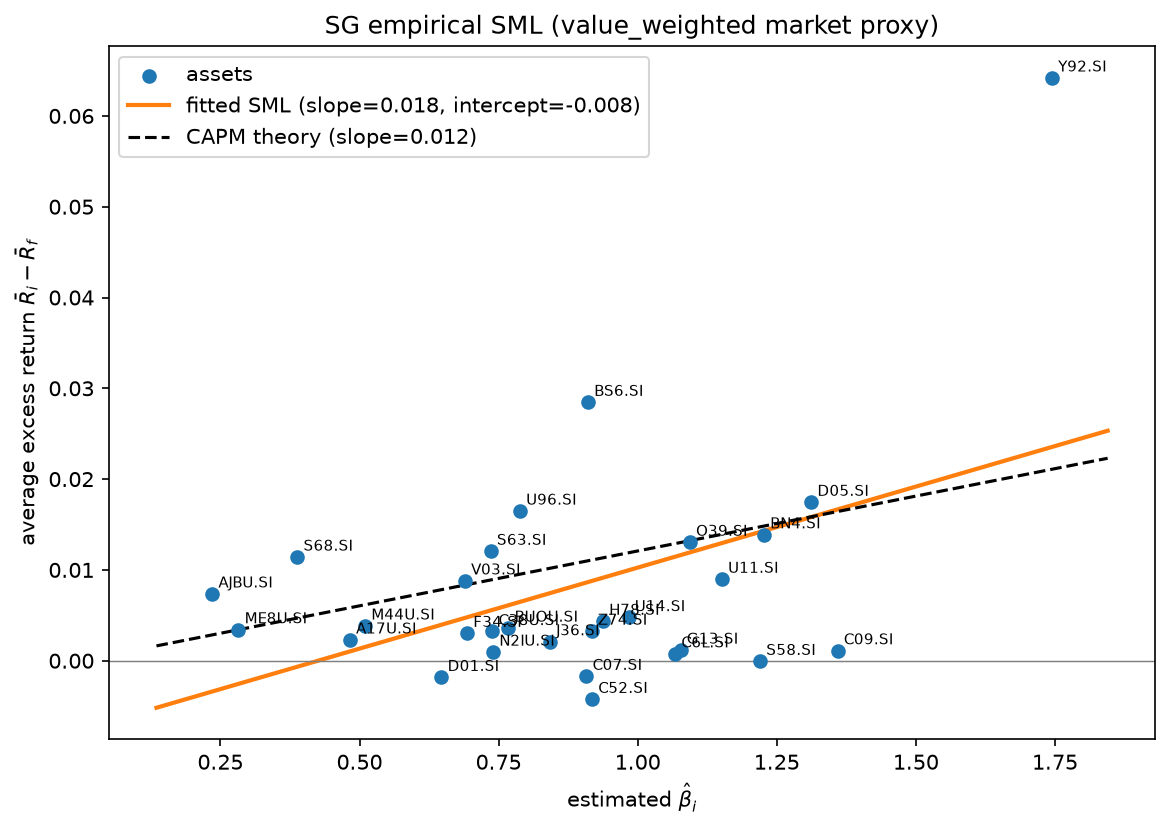

In [3]:
for universe, result in RESULTS.items():
    print(f"--- {universe} ---")
    display(Image(filename=result.output_paths["sml"]))

## (2c) / (2d) Joint alpha test and SML vs theory
GRS tests whether all alphas are jointly zero. With many assets, one or two
|t| > 2 are expected by chance; compare the significant count with that.

In [4]:
summary = pd.DataFrame(
    {
        universe: {
            "assets": int(result.fit.n),
            "fitted slope": result.fit.slope,
            "fitted intercept": result.fit.intercept,
            "theory slope": result.fit.theoretical_slope,
            "R2 of SML": result.fit.r_squared,
            "alphas p<0.05": int((result.table["p_alpha"] < 0.05).sum()),
            "GRS F": result.grs["f_stat"],
            "GRS p": result.grs["p_value"],
        }
        for universe, result in RESULTS.items()
    }
).T
summary.round(4)

,assets,fitted slope,fitted intercept,theory slope,R2 of SML,alphas p<0.05,GRS F,GRS p
us,30.0,0.0163,0.0004,0.0191,0.6100,2.0,1.0085,0.4692
sg,29.0,0.0178,-0.0076,0.0121,0.2143,6.0,1.4876,0.0807


## Proxy swap (preview of Stage 4)
Because the market proxy is an argument, Roll's critique is one loop: here
the US CAPM is re-run on our own cap-weighted composite versus the
Fama–French market. Betas and the GRS verdict can move materially.

In [5]:
returns = load_returns(universe="us")
ff3 = load_ff3()
for method in ["value_weighted", "ff_market"]:
    result = run_capm_analysis(returns, universe="us", method=method, ff3=ff3)
    print(
        f"{method:14s} beta range {result.table['beta'].min():+.2f}.."
        f"{result.table['beta'].max():+.2f}, "
        f"sig alphas {int((result.table['p_alpha'] < 0.05).sum()):2d}, "
        f"GRS p {result.grs['p_value']:.3f}"
    )

value_weighted beta range +0.12..+1.85, sig alphas  2, GRS p 0.469
ff_market      beta range +0.25..+1.75, sig alphas  1, GRS p 0.190


/var/folders/r9/dyfdvd_j5_15pz3fkwg9rjr40000gn/T/ipykernel_78542/3303218387.py:4: UserWarning: us: 1 month(s) of returns are not covered by the factor file; estimating on the common sample.
  result = run_capm_analysis(returns, universe="us", method=method, ff3=ff3)


## Takeaways to carry into the report

- The fitted SML is much flatter than theory in both universes, with a small
  (US) to negative (SG) intercept — the classic empirical CAPM result.
- The GRS test and the count of |t| > 2 should be read together: a handful of
  significant alphas is expected by chance, a GRS rejection is stronger.
- Both universes' numbers depend on the market proxy; Stage 4 reports the
  proxy-swap table as the Roll exhibit.

**Data caveats** (carry into the report): Yahoo adjusted closes; today's
index members backfilled (survivorship); SG currently uses a documented
constant risk-free rate until a MAS/SORA series is committed.